# Case study: Microsoft (MSFT) - a DCF built on SEC EDGAR data

This notebook walks through a full discounted cash flow valuation of Microsoft using the
`dcf` package in this repository:

1. pull 10-K financials from the official SEC EDGAR `companyfacts` API,
2. derive the WACC (CAPM cost of equity, after-tax cost of debt, market-value weights),
3. project unlevered free cash flow under bull / base / bear scenarios,
4. compare a Gordon-growth terminal value with an exit-multiple terminal value,
5. stress the result with a WACC x terminal growth grid and a reverse DCF.

**Not investment advice.** The assumptions in `config/msft.yaml` are illustrative judgement
calls made for a learning project. All numbers below are produced by the code at run time
(SEC data and the yfinance share price as of the execution date); re-running the notebook
later will give different numbers.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from dcf.assumptions import load_assumptions
from dcf.financials import historical_ufcf, revenue_growth_rates, safe_ratio
from dcf.market import YFinanceProvider, resolve_quote
from dcf.model import company_from_facts, prepare_company, run_dcf
from dcf.sec_client import SecClient

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# The SEC asks for a User-Agent "Name email". Set SEC_USER_AGENT in your shell before
# starting Jupyter: without it the client refuses to download and only a fresh local cache
# (.cache/sec, 7 days) can be used.
print("SEC_USER_AGENT set:", bool(os.environ.get("SEC_USER_AGENT")))

assumptions = load_assumptions(ROOT / "config" / "msft.yaml")
pd.options.display.float_format = "{:,.1f}".format

SEC_USER_AGENT set: False


## 1. Historical financials from SEC EDGAR

`SecClient` maps the ticker to its CIK via `company_tickers.json`, downloads the
`companyfacts` JSON (cached locally in `.cache/sec`) and `extract_fiscal_years` keeps only
full-year values from 10-K filings. For each line item an ordered list of XBRL tags is
tried; the table at the end of this section shows which tag was actually used.
`prepare_company` applies the lease treatment from the YAML (default: finance leases are
debt, so assets obtained under finance leases are added to capex).

In [2]:
client = SecClient(cache_dir=ROOT / ".cache" / "sec")
cik, title = client.ticker_to_cik("MSFT")
company = prepare_company(company_from_facts("MSFT", client.company_facts(cik)), assumptions)
years = company.fiscal_years
tax = assumptions.tax_rate

hist = pd.DataFrame(
    {
        f"FY{y.fiscal_year}": {
            "Revenue": y.revenue / 1e6,
            "Revenue growth %": (g * 100) if g is not None else None,
            "EBIT": (y.ebit or 0) / 1e6,
            "EBIT margin %": safe_ratio(y.ebit, y.revenue) * 100,
            "D&A": (y.depreciation_amortization or 0) / 1e6,
            "Capex incl. finance leases": (y.capex or 0) / 1e6,
            "  of which finance leases": (y.finance_lease_additions or 0) / 1e6,
            "Capex % revenue": safe_ratio(y.capex, y.revenue) * 100,
            "Operating NWC": y.net_working_capital / 1e6,
            "UFCF": (u / 1e6) if u is not None else None,
            "Financial debt": y.total_debt / 1e6,
            "Finance lease liabilities": (y.finance_lease_liabilities or 0) / 1e6,
        }
        for y, g, u in zip(years, revenue_growth_rates(years), historical_ufcf(years, tax))
    }
)
print(f"{company.name}, CIK {cik} - USD millions")
hist

MICROSOFT CORP, CIK 789019 - USD millions


,FY2022,FY2023,FY2024,FY2025,FY2026
Revenue,"198,270.0","211,915.0","245,122.0","281,724.0","331,839.0"
Revenue growth %,NaN,6.9,15.7,14.9,17.8
EBIT,"83,383.0","88,523.0","109,433.0","128,528.0","155,237.0"
EBIT margin %,42.1,41.8,44.6,45.6,46.8
D&A,"15,580.0","14,852.0","21,800.0","31,408.0","44,403.0"
Capex incl. finance leases,"28,120.0","31,235.0","56,110.0","85,062.0","140,556.0"
of which finance leases,"4,234.0","3,128.0","11,633.0","20,511.0","24,608.0"
Capex % revenue,14.2,14.7,22.9,30.2,42.4
Operating NWC,"-16,535.0","-17,808.0","-21,408.0","-21,436.0","-33,108.0"
UFCF,NaN,"54,823.2","55,742.1","47,911.1","38,156.2"


In [3]:
pd.Series(company.latest.sources, name="XBRL tag used (latest FY)").to_frame()

,XBRL tag used (latest FY)
revenue,RevenueFromContractWithCustomerExcludingAssess...
ebit,OperatingIncomeLoss
depreciation_amortization,Depreciation + AmortizationOfIntangibleAssets ...
capex,PaymentsToAcquirePropertyPlantAndEquipment + R...
income_tax_expense,IncomeTaxExpenseBenefit
pretax_income,IncomeLossFromContinuingOperationsBeforeIncome...
diluted_shares,WeightedAverageNumberOfDilutedSharesOutstanding
basic_shares,WeightedAverageNumberOfSharesOutstandingBasic
receivables,AccountsReceivableNetCurrent
inventory,InventoryNet


**Reading the history (as of the FY2026 10-K).** Revenue growth has been strong and the operating margin has
expanded. The striking line is capex: spending on data centres for AI has grown far faster
than revenue, so free cash flow has *not* kept pace with operating income. Any valuation of
Microsoft hinges on whether this capex intensity is temporary (a build-out that normalises)
or structural.

Finance leases are a large part of the build-out. Assets obtained under new finance leases
(USD 24.6bn in FY2026) never appear in cash capex, and the finance-lease liability has grown
past Microsoft's financial debt. The model therefore adds the lease-financed assets to capex
and subtracts the liability in the equity bridge, as if the data centres had been bought
with borrowed money.

Data caveat: Microsoft reports D&A in its cash flow statement under a company-specific tag
that the standard-taxonomy `companyfacts` API does not include. The loader therefore falls
back to `Depreciation + AmortizationOfIntangibleAssets` and adds finance-lease ROU
amortisation, which can still differ from the reported total.

## 2. Market data and WACC

Price and beta come from yfinance behind the `MarketDataProvider` interface; both can be
overridden in YAML. The risk-free rate (10-year Treasury, FRED DGS10) and the equity risk
premium (Damodaran's implied ERP) are dated snapshots in `src/dcf/defaults.yaml`.

In [4]:
quote = resolve_quote("MSFT", YFinanceProvider(), assumptions.market.price, assumptions.market.beta)
base = run_dcf(company, quote, assumptions, "base")
w, wi = base.wacc, base.wacc_inputs
pd.Series(
    {
        "Share price (USD)": f"{quote.price:,.2f}",
        "Beta": f"{wi.beta:.2f}",
        "Risk-free rate": f"{wi.risk_free_rate:.2%}",
        "Equity risk premium": f"{wi.equity_risk_premium:.2%}",
        "Cost of equity (CAPM)": f"{w.cost_of_equity:.2%}",
        "Pre-tax cost of debt": f"{wi.pretax_cost_of_debt:.2%}",
        "After-tax cost of debt": f"{w.after_tax_cost_of_debt:.2%}",
        "E/V": f"{w.equity_weight:.1%}",
        "D/V": f"{w.debt_weight:.1%}",
        "WACC": f"{w.wacc:.2%}",
    },
    name=f"{quote.source}, {quote.as_of}",
).to_frame()

,"yfinance, 2026-11-02"
Share price (USD),523.91
Beta,1.04
Risk-free rate,4.98%
Equity risk premium,4.20%
Cost of equity (CAPM),9.37%
Pre-tax cost of debt,5.58%
After-tax cost of debt,4.41%
E/V,97.3%
D/V,2.7%
WACC,9.24%


Microsoft has very little debt (including finance leases) relative to its market
capitalisation, so the WACC is almost identical to the cost of equity. That makes the result highly sensitive to beta and the
equity risk premium - two inputs that are estimates, not facts.

## 3. Base case: unlevered free cash flow

UFCF = EBIT x (1 - t) + D&A - capex - increase in NWC. In the base case growth fades from
15% to the 3% terminal rate over seven years, the EBIT margin drifts down to 44% as
depreciation from the capex wave hits the P&L, and capex intensity (including finance
leases) normalises from 40% to 18% of revenue, still above D&A at 15% (positive net
reinvestment).

In [5]:
proj = pd.DataFrame(
    {
        f"FY{r.fiscal_year}E": {
            "Growth %": r.revenue_growth * 100,
            "Revenue": r.revenue / 1e6,
            "EBIT margin %": r.ebit_margin * 100,
            "NOPAT": r.nopat / 1e6,
            "+ D&A": r.depreciation_amortization / 1e6,
            "- Capex": r.capex / 1e6,
            "- dNWC": r.delta_nwc / 1e6,
            "UFCF": r.ufcf / 1e6,
        }
        for r in base.projection
    }
)
proj

,FY2027E,FY2028E,FY2029E,FY2030E,FY2031E,FY2032E,FY2033E
Growth %,15.0,13.0,11.0,9.0,7.0,5.0,3.0
Revenue,"381,614.8","431,224.8","478,659.5","521,738.9","558,260.6","586,173.6","603,758.8"
EBIT margin %,46.4,46.0,45.6,45.2,44.8,44.4,44.0
NOPAT,"139,835.2","156,660.4","172,390.9","186,268.6","197,555.4","205,593.6","209,866.6"
+ D&A,"50,700.3","58,523.4","66,328.5","73,788.8","80,549.0","86,251.3","90,563.8"
- Capex,"140,652.3","145,384.4","146,333.0","143,105.5","135,577.6","123,933.8","108,676.6"
- dNWC,-371.8,"-4,352.4","-4,161.5","-3,779.4","-3,204.1","-2,448.9","-1,542.8"
UFCF,"50,254.9","74,151.8","96,547.9","120,731.3","145,731.0","170,359.8","193,296.6"


## 4. Terminal value: Gordon growth vs. exit multiple

In [6]:
g, x = base.gordon, base.exit_multiple
def tv_column(v):
    return {
        "Terminal value (USD m)": v.terminal_value / 1e6,
        "PV of terminal value": v.pv_terminal / 1e6,
        "PV of explicit FCF": v.pv_explicit / 1e6,
        "Enterprise value": v.enterprise_value / 1e6,
        "- Debt": base.bridge.debt / 1e6,
        "- Finance lease liabilities": base.bridge.lease_liabilities / 1e6,
        "+ Cash & ST investments": base.bridge.cash / 1e6,
        "= Equity value": v.equity_value / 1e6,
        "Value per share (USD)": v.value_per_share,
        "TV share of EV %": v.terminal_share_of_ev * 100,
    }


print("Share count:", base.bridge.shares_source)
pd.DataFrame({"Gordon growth": tv_column(g), "Exit multiple": tv_column(x)})

Share count: shares outstanding 2026-10-22 (cover page) + FY2026 dilution (diluted - basic weighted average)


,Gordon growth,Exit multiple
Terminal value (USD m),"3,192,283.5","6,411,918.7"
PV of terminal value,"1,797,644.6","3,454,665.2"
PV of explicit FCF,"590,634.0","590,634.0"
Enterprise value,"2,388,278.7","4,045,299.2"
- Debt,"40,294.0","40,294.0"
- Finance lease liabilities,"66,594.0","66,594.0"
+ Cash & ST investments,"76,843.0","76,843.0"
= Equity value,"2,358,233.7","4,015,254.2"
Value per share (USD),316.5,538.9
TV share of EV %,75.3,85.4


In [7]:
ck = base.checks
print(f"Current price:                         USD {quote.price:,.2f}")
print(f"Gordon value per share:                USD {g.value_per_share:,.2f} ({g.upside:+.1%})")
print(f"Exit-multiple value per share:         USD {x.value_per_share:,.2f} ({x.upside:+.1%})")
# The cross-checks are None when the final-year cash flow or EBITDA is not positive.
print(f"Gordon TV implies exit multiple of     {ck.implied_exit_multiple:.1f}x EBITDA")
print(f"Exit multiple implies perpetual growth {ck.implied_perpetual_growth:.1%}")
print(f"Terminal value share of EV (Gordon)    {g.terminal_share_of_ev:.0%}")
print(f"Implied ROIC on new capital            {ck.implied_terminal_roic:.1%} "
      f"(WACC {base.wacc.wacc:.2%})")
for message in base.warnings:
    print("warning:", message)

Current price:                         USD 523.91
Gordon value per share:                USD 316.53 (-39.6%)
Exit-multiple value per share:         USD 538.95 (+2.9%)
Gordon TV implies exit multiple of     9.4x EBITDA
Exit multiple implies perpetual growth 5.9%
Terminal value share of EV (Gordon)    75%
Implied ROIC on new capital            38.0% (WACC 9.24%)


**Why the two methods disagree.** The cross-checks translate one method into the language
of the other. If the exit multiple implies a perpetual growth rate well above long-run
nominal GDP growth, the multiple is effectively assuming that today's premium valuation
lasts forever. Conversely, the Gordon TV implies an EV/EBITDA multiple far below the exit
multiple assumed in the scenario. Neither is "right": the gap is the point - it shows how
much of the market price rests on the terminal assumptions. In both methods the terminal
value is the majority of enterprise value.

## 5. Scenarios

In [8]:
results = {name: run_dcf(company, quote, assumptions, name, with_sensitivity=False)
           for name in ("bear", "base", "bull")}
summary = pd.DataFrame(
    {
        name: {
            "Growth year 1 %": r.scenario.revenue_growth[0] * 100,
            "EBIT margin final %": r.scenario.ebit_margin[-1] * 100,
            "Terminal growth %": r.scenario.terminal_growth * 100,
            "Exit multiple (x)": r.scenario.exit_multiple,
            "Gordon value/share": r.gordon.value_per_share,
            "Exit value/share": r.exit_multiple.value_per_share,
        }
        for name, r in results.items()
    }
)
summary

,bear,base,bull
Growth year 1 %,10.0,15.0,19.0
EBIT margin final %,40.0,44.0,47.0
Terminal growth %,2.5,3.0,3.5
Exit multiple (x),14.0,18.0,22.0
Gordon value/share,219.3,316.5,428.0
Exit value/share,349.6,538.9,766.6


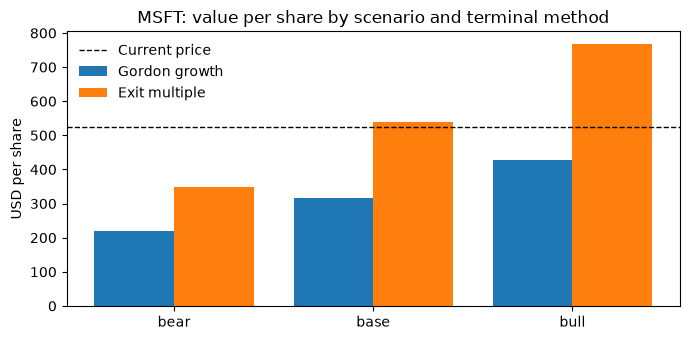

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
names = list(results)
pos = range(len(names))
ax.bar([p - 0.2 for p in pos], [results[n].gordon.value_per_share for n in names], 0.4,
       label="Gordon growth")
ax.bar([p + 0.2 for p in pos], [results[n].exit_multiple.value_per_share for n in names], 0.4,
       label="Exit multiple")
ax.axhline(quote.price, color="black", linestyle="--", linewidth=1, label="Current price")
ax.set_xticks(list(pos), names)
ax.set_ylabel("USD per share")
ax.set_title("MSFT: value per share by scenario and terminal method")
ax.legend(frameon=False)
plt.tight_layout()
fig.savefig(ROOT / "docs" / "msft_scenarios.png", dpi=100)  # the chart used in the README
plt.show()

## 6. Sensitivity: WACC x terminal growth (Gordon, base case)

In [10]:
s = base.sensitivity
grid = pd.DataFrame(
    s.values,
    index=[f"{v:.2%}" for v in s.waccs],
    columns=[f"{v:.2%}" for v in s.growths],
)
grid.index.name = "WACC \\ g"
grid.style.format("{:,.0f}").background_gradient(cmap="RdYlGn", axis=None)

,2.00%,2.50%,3.00%,3.50%,4.00%
WACC \ g,,,,,
8.24%,332,355,383,417,459
8.74%,305,324,347,374,407
9.24%,281,298,317,339,365
9.74%,261,275,291,309,331
10.24%,243,255,268,284,302


Moving the WACC by half a percentage point or the terminal growth rate by half a point
changes the value per share by a large amount. A single DCF point estimate should
therefore always be read together with this grid.

## 7. Reverse DCF: what is priced in?

Holding the base case margins, reinvestment, WACC and terminal growth fixed, `brentq` solves
for the *constant* annual revenue growth over the seven explicit years at which the Gordon
value per share equals today's share price.

In [11]:
if base.implied_growth is None:
    print("No growth rate between -50% and +100% p.a. reproduces the current price.")
else:
    print(f"Price USD {quote.price:,.2f} implies {base.implied_growth:.1%} revenue growth p.a. "
          f"for {base.scenario.years} years, versus {base.scenario.revenue_growth[0]:.1%} "
          f"fading to {base.scenario.terminal_growth:.1%} in the base case.")

Price USD 523.91 implies 17.4% revenue growth p.a. for 7 years, versus 15.0% fading to 3.0% in the base case.


## 8. Mid-year convention

Cash arrives throughout the year, not on the last day. The mid-year convention discounts
each year's cash flow by t - 0.5 years instead of t.

In [12]:
end_year = load_assumptions(ROOT / "config" / "msft.yaml",
                            {"projection": {"mid_year_convention": False}})
eoy = run_dcf(company, quote, end_year, "base", with_sensitivity=False)
print(f"Gordon value per share, mid-year:    USD {base.gordon.value_per_share:,.2f}")
print(f"Gordon value per share, end-of-year: USD {eoy.gordon.value_per_share:,.2f}")
print(f"Difference: {base.gordon.value_per_share / eoy.gordon.value_per_share - 1:+.1%}")

Gordon value per share, mid-year:    USD 316.53
Gordon value per share, end-of-year: USD 302.68
Difference: +4.6%


## 9. Takeaways and limitations

- The valuation is driven by a few inputs: the equity risk premium and beta (via WACC), the
  terminal growth rate or exit multiple, and how quickly capex intensity normalises.
- The terminal value accounts for most of enterprise value. The explicit years still
  matter, but mainly through the terminal-year cash flow and EBITDA they produce (margin,
  capex and D&A in year 7), which the terminal value is built on, rather than through
  their own discounted cash flows.
- The reverse DCF reframes the question from "what is it worth?" to "what do I have to
  believe to justify the price?" - usually a more useful conversation.
- Leases matter here: the finance-lease liability (USD 66.6bn) is larger than the financial
  debt and costs about USD 9 per share in the bridge, and lease-financed assets lift FY2026
  capex from 35% to 42% of revenue.
- Limitations: operating leases stay in EBIT as rent (their liability is not subtracted);
  minority interests, stock-based compensation, equity investments and pension items are
  not part of the equity bridge; XBRL tag coverage is imperfect (D&A here is a proxy, and
  whether Microsoft's depreciation note already includes finance-lease amortisation is not
  visible in XBRL); book values proxy for the market value of debt and leases; the share
  count is the latest cover-page figure plus last year's dilution; beta from Yahoo is a
  backward-looking regression estimate.

*Educational model, not investment advice.*